# Import

In [22]:
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import random
import math
from concurrent.futures import ThreadPoolExecutor

# Path

In [7]:
EXPERIMENT_LOG_PATH = 'E:/Gun/model-benchmark/scratch/lt200264-saiwat/worm-project/worm-classification-model/model-benchmark/all_results.xlsx'
DATASETS_DIR = 'E:/Gun/worm-project/datasets'

In [8]:
val_extension = {'.png'}

# EDA

In [9]:
datasets_dir = Path(DATASETS_DIR)
cls_folders = [folder for folder in datasets_dir.glob('cls*') if folder.is_dir()]

## Histogram

In [58]:
def get_dims(img_path):
    with Image.open(img_path) as img:
        w, h = img.size
    return {
        'path': str(img_path),
        'split': img_path.parent.parent.name,   # train / val / test
        'class': img_path.parent.name,          # class folder
        'width': w,
        'height': h,
        'aspect_ratio': w / h,
        'max_side': max(w, h),
        'min_side': min(w, h),
    }


def iqr_fences(values, k=1.5, log=False):
    """Tukey fences. log=True -> compute on log scale (for ratios / skewed sizes)."""
    x = np.log(values) if log else np.asarray(values, dtype=float)
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    if log:
        lo, hi = np.exp(lo), np.exp(hi)
    return lo, hi


def extract_image_property(dataset_folder, candidate_sizes=(160, 192, 224, 256, 320),
                           iqr_k=1.5, fence_split='train', save_csv=None):
    dataset_folder = Path(dataset_folder)
    img_paths = [p for p in dataset_folder.rglob('*') if p.suffix.lower() in val_extension]

    with ThreadPoolExecutor() as executor:
        dimensions = list(executor.map(get_dims, img_paths))

    df = pd.DataFrame(dimensions)

    # ---------------- data-driven fences (fit on train only) ----------------
    ref = df[df['split'] == fence_split]
    if ref.empty:
        print(f"⚠️ no '{fence_split}' split found, fitting fences on all images")
        ref = df
    ar_lo, ar_hi = iqr_fences(ref['aspect_ratio'], k=iqr_k, log=True)
    side_lo, _ = iqr_fences(ref['min_side'], k=iqr_k, log=True)

    df['flag_ar_wide'] = df['aspect_ratio'] > ar_hi
    df['flag_ar_tall'] = df['aspect_ratio'] < ar_lo
    df['flag_tiny'] = df['min_side'] < side_lo
    df['is_outlier'] = df[['flag_ar_wide', 'flag_ar_tall', 'flag_tiny']].any(axis=1)
    df['outlier_reason'] = (
        df['flag_ar_wide'].map({True: 'wide;', False: ''}) +
        df['flag_ar_tall'].map({True: 'tall;', False: ''}) +
        df['flag_tiny'].map({True: 'tiny;', False: ''})
    ).str.rstrip(';')
    # symmetric extremeness for sorting: 0.1 and 10 are equally extreme
    df['ar_extreme'] = np.maximum(df['aspect_ratio'], 1 / df['aspect_ratio'])

    # ---------------- plots ----------------
    plt.figure(figsize=(10, 13))

    plt.subplot(4, 1, 1)
    sns.histplot(df['width'], color='blue', kde=True, label='Width', element='step', alpha=0.4, bins=50)
    plt.title('Width Histogram', fontsize=16, fontweight='bold')
    plt.xlabel('width (pixel)')
    plt.legend()

    plt.subplot(4, 1, 2)
    sns.histplot(df['height'], color='orange', kde=True, label='Height', element='step', alpha=0.4, bins=50)
    plt.title('Height Histogram', fontsize=16, fontweight='bold')
    plt.xlabel('height (pixel)')
    plt.legend()

    plt.subplot(4, 1, 3)
    sns.histplot(df['max_side'], color='purple', kde=True, element='step', alpha=0.4, bins=50)
    for s in candidate_sizes:
        plt.axvline(s, linestyle='--', linewidth=1, color='red')
        plt.text(s, plt.ylim()[1] * 0.9, f' {s}', color='red')
    plt.title('Longest Side Histogram (max(width, height))', fontsize=16, fontweight='bold')
    plt.xlabel('longest side (pixel)')

    plt.subplot(4, 1, 4)
    sns.histplot(df['aspect_ratio'], color='green', kde=True, bins=100, log_scale=True)
    for f in (ar_lo, ar_hi):
        plt.axvline(f, linestyle='--', linewidth=1, color='red')
        plt.text(f, plt.ylim()[1] * 0.9, f' {f:.2f}', color='red')
    plt.title(f'Aspect Ratio (log scale) with IQR fences (k={iqr_k})', fontsize=16, fontweight='bold')
    plt.xlabel('aspect ratio (width / height), log scale')

    plt.tight_layout()
    plt.show()

    # ---------------- numbers ----------------
    print(f"Total images: {len(df)}\n")
    print(df[['width', 'height', 'max_side', 'min_side', 'aspect_ratio']].describe().round(2))

    print("\nLongest-side percentiles:")
    for p in [50, 75, 90, 95, 99, 99.9]:
        print(f"  p{p:<5}: {np.percentile(df['max_side'], p):.0f} px")

    print("\nImages that fit WITHOUT resize (pad only):")
    for s in candidate_sizes:
        print(f"  <= {s}px: {(df['max_side'] <= s).mean() * 100:6.2f}%")

    print("\nLongest side per class (median / p95):")
    print(df.groupby('class')['max_side'].describe(percentiles=[0.5, 0.95])[['count', '50%', '95%', 'max']].round(0))

    # ---------------- outliers ----------------
    print(f"\nIQR fences (log scale, k={iqr_k}, fitted on '{fence_split}'):")
    print(f"  aspect ratio : {ar_lo:.3f} .. {ar_hi:.2f}  (≈ 1:{1 / ar_lo:.1f} .. {ar_hi:.1f}:1)")
    print(f"  shortest side: < {side_lo:.1f} px")

    outliers = df[df['is_outlier']].sort_values('ar_extreme', ascending=False)
    print(f"\nOutliers: {len(outliers)} images ({len(outliers) / len(df) * 100:.2f}%)")
    print("\nBy reason:")
    print(outliers['outlier_reason'].value_counts())
    print("\nBy split / class:")
    print(outliers.groupby(['split', 'class']).size())
    print("\nOutlier rate per class (%):")
    print((df.groupby('class')['is_outlier'].mean() * 100).round(2))
    print("\nTop 20 most extreme:")
    print(outliers[['path', 'width', 'height', 'aspect_ratio', 'outlier_reason']]
          .head(20).to_string(index=False))

    if save_csv:
        outliers.drop(columns=['flag_ar_wide', 'flag_ar_tall', 'flag_tiny']).to_csv(save_csv, index=False)
        print(f"\nSaved full outlier list to {save_csv}")

    return df, outliers

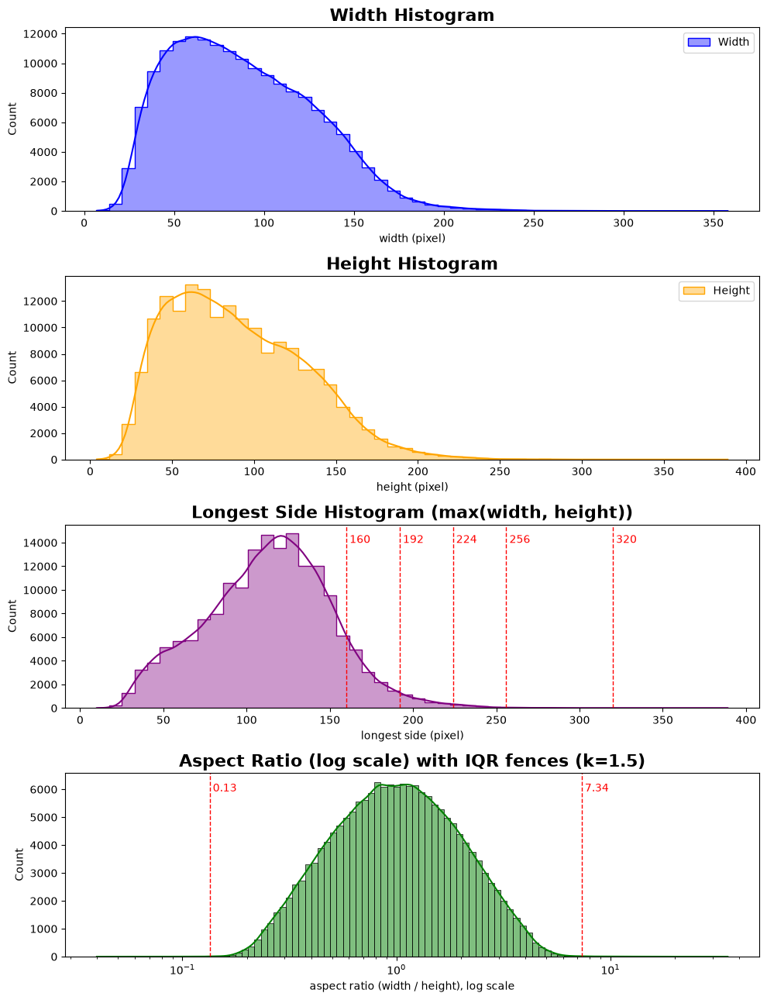

Total images: 172903

           width     height   max_side   min_side  aspect_ratio
count  172903.00  172903.00  172903.00  172903.00     172903.00
mean       88.45      89.97     113.27      65.14          1.25
std        39.03      41.22      38.10      24.76          0.90
min         7.00       4.00      10.00       4.00          0.04
25%        57.00      57.00      88.00      46.00          0.60
50%        84.00      84.00     115.00      63.00          0.99
75%       116.00     119.00     138.00      81.00          1.64
max       358.00     389.00     389.00     206.00         35.29

Longest-side percentiles:
  p50   : 115 px
  p75   : 138 px
  p90   : 159 px
  p95   : 173 px
  p99   : 208 px
  p99.9 : 252 px

Images that fit WITHOUT resize (pad only):
  <= 160px:  90.63%
  <= 192px:  97.92%
  <= 224px:  99.54%
  <= 256px:  99.92%
  <= 320px:  99.99%

Longest side per class (median / p95):
           count    50%    95%    max
class                                
Other    8805

(                                                     path split    class  \
 0       E:\Gun\worm-project\datasets\cls2_blackout\tes...  test    Other   
 1       E:\Gun\worm-project\datasets\cls2_blackout\tes...  test    Other   
 2       E:\Gun\worm-project\datasets\cls2_blackout\tes...  test    Other   
 3       E:\Gun\worm-project\datasets\cls2_blackout\tes...  test    Other   
 4       E:\Gun\worm-project\datasets\cls2_blackout\tes...  test    Other   
 ...                                                   ...   ...      ...   
 172898  E:\Gun\worm-project\datasets\cls2_blackout\val...   val  Perfect   
 172899  E:\Gun\worm-project\datasets\cls2_blackout\val...   val  Perfect   
 172900  E:\Gun\worm-project\datasets\cls2_blackout\val...   val  Perfect   
 172901  E:\Gun\worm-project\datasets\cls2_blackout\val...   val  Perfect   
 172902  E:\Gun\worm-project\datasets\cls2_blackout\val...   val  Perfect   
 
         width  height  aspect_ratio  max_side  min_side  flag_ar_wide  \


In [59]:
# print(cls_folders[0])
extract_image_property(cls_folders[0])

## Class distribute

In [ ]:
def plot_class_stat(dataset_folder):
    data = []
    
    # loop folder
    for split_name in ['train', 'val', 'test']:
        # get train val test folder
        split_dir = dataset_folder / split_name
        
        if not split_dir.exists():
            continue
        
        # loop through subfolder
        for class_dir in split_dir.iterdir():
            if class_dir.is_dir():
                class_name = class_dir.name
                
                # len images
                img_count = sum(1 for file in class_dir.iterdir() if file.is_file() and file.suffix.lower() in val_extension)
                
                # save
                data.append({
                    'Split': split_name,
                    'Class': class_name,
                    'Count': img_count,
                })
                
    # plot graph
    df = pd.DataFrame(data)
    
    if not df.empty:
        # devide data
        df_pivot = df.pivot(index='Class', columns='Split', values='Count').fillna(0)
        
        col_order = [c for c in ['train', 'val', 'test'] if c in df_pivot.columns]
        df_pivot = df_pivot[col_order]
        
        colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
        split_totals = df_pivot.sum(axis=1)
        grand_total = sum(split_totals)
        
        stats_text = f'Dataset Statistics:\n'
        stats_text += f'Total Images: {int(grand_total):,}\n\n'
        stats_text += 'Class Distribution:\n'
        
        # calculate % of each class
        for cls in df_pivot.index:
            cls_total = df_pivot.loc[cls].sum()
            percent = (cls_total / grand_total) * 100
            stats_text += f'• {cls}: {percent:.1f}%\n'
        
        # plot bar
        ax = df_pivot.plot(kind='barh', stacked=True, figsize=(12, 5), color=colors, width=0.7)
        
        plt.title(f'Class Distribution of {dataset_folder.name}', fontsize=15, fontweight='bold', pad=15)
        plt.xlabel('Number of Images', fontsize=12, labelpad=15)
        plt.ylabel('Class', fontsize=12, labelpad=15)
        
        plt.legend(title='Dataset Split', bbox_to_anchor=(1.05, 1), loc='upper left')
        
        # top bar number
        for i, total in enumerate(split_totals):
            ax.text(total, i, f'  {int(total):,}', va='center', ha='left', color='black', fontsize=12, fontweight='bold')
        
        # inside number
        label_threshold = 6000
        for c in ax.containers:
            ax.bar_label(c, label_type='center', color='white', fontsize=12, fontweight='bold', fmt=lambda x: f'{int(x):,}' if x >= label_threshold else '')
            
        ax.set_xlim(right=split_totals.max() * 1.15)
        
        # plot status legend
        ax.text(1.02, 0.7, stats_text, transform=ax.transAxes, fontsize=11, verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='lightgray'))
        
        plt.tight_layout()
        plt.show()
    else:
        print("No images found. Ensure your script is running in the same directory")
        

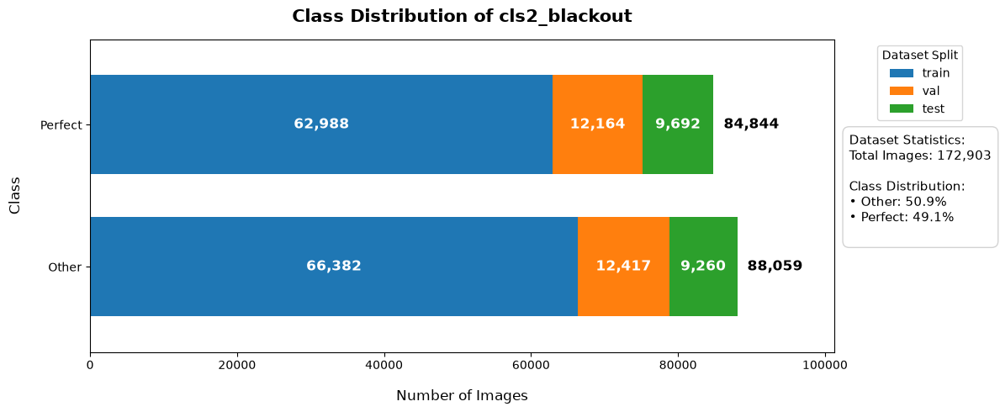

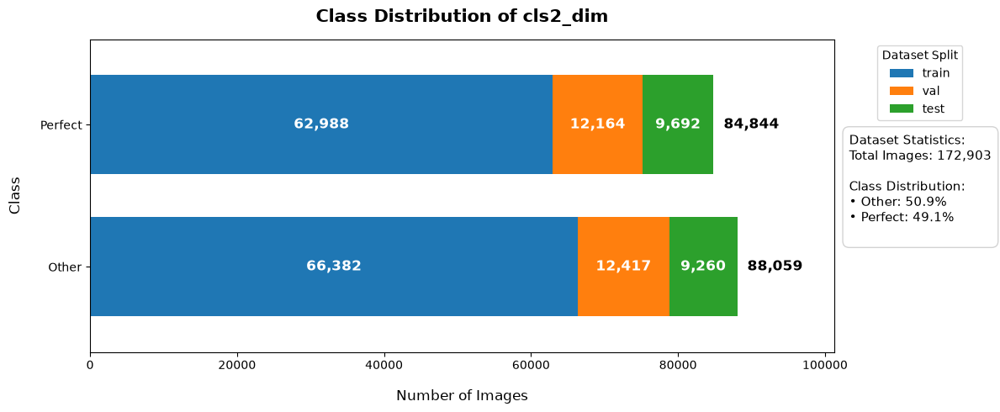

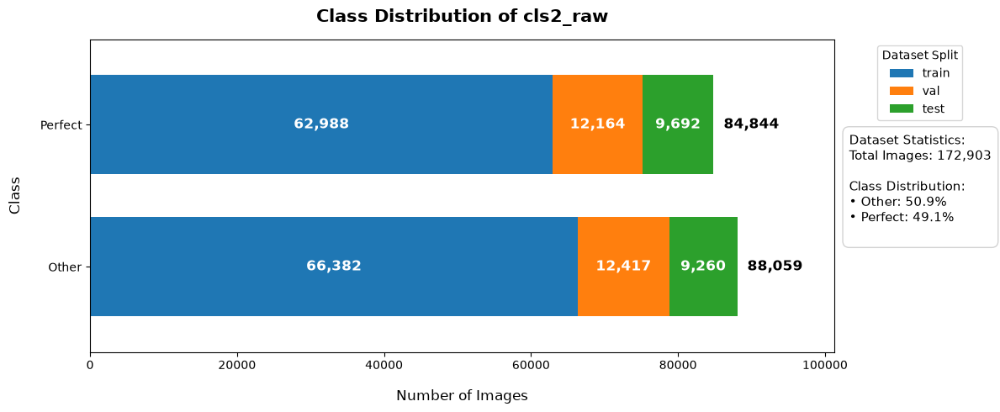

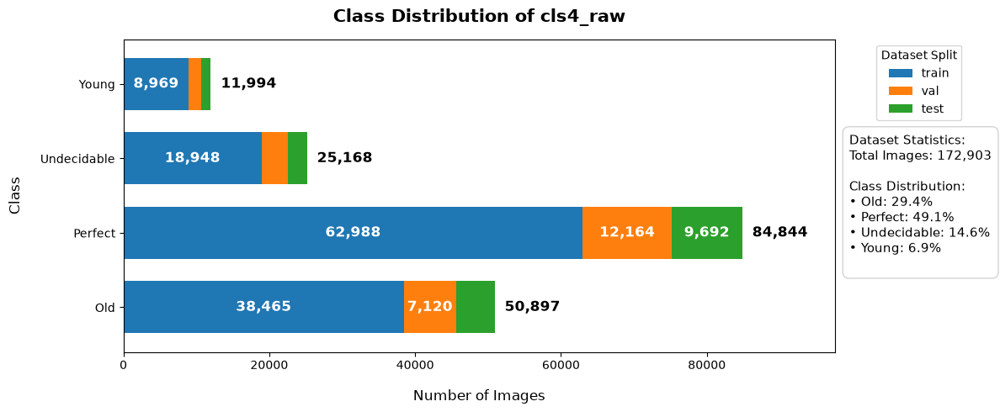

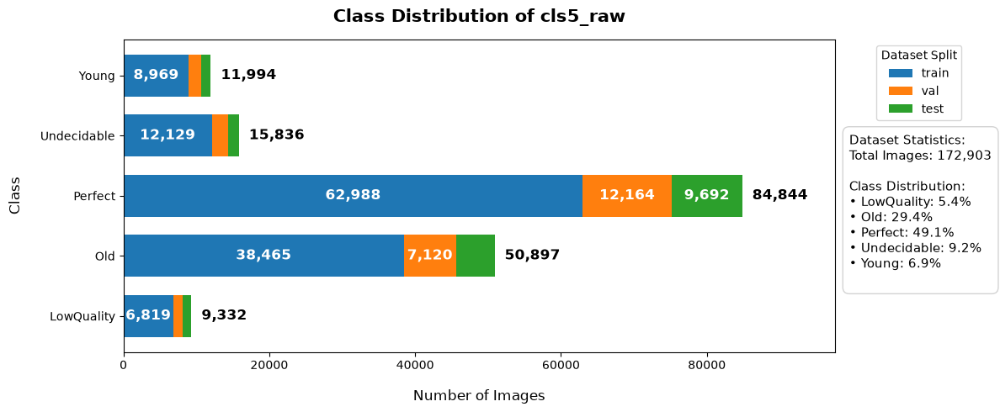

In [ ]:
# plot_class_stat(cls_folders[0])
for dataset in cls_folders:
    plot_class_stat(dataset)

In [ ]:
def plot_image_size_stats(dataset_folder):
    data = []
    
    print(f"กำลังสแกนขนาดภาพใน: {dataset_folder} ...")
    
    # โครงสร้างลูปเหมือนโค้ดของคุณ
    for split_name in ['train', 'val', 'test']:
        split_dir = dataset_folder / split_name
        
        if not split_dir.exists():
            continue
            
        for class_dir in split_dir.iterdir():
            if class_dir.is_dir():
                class_name = class_dir.name
                
                # อ่านไฟล์รูปภาพทั้งหมดในคลาสนี้
                for file in class_dir.iterdir():
                    if file.is_file() and file.suffix.lower() in val_extension:
                        try:
                            # ดึงแค่ขนาดภาพ ไม่โหลดเต็มเพื่อความรวดเร็ว
                            with Image.open(file) as img:
                                w, h = img.size
                                data.append({
                                    'Split': split_name,
                                    'Class': class_name,
                                    'Width': w,
                                    'Height': h,
                                    'Aspect Ratio': w/h
                                })
                        except:
                            continue # ข้ามไฟล์ที่เสีย
                            
    df = pd.DataFrame(data)
    
    if not df.empty:
        # คำนวณสถิติที่จำเป็น
        total_imgs = len(df)
        med_w, med_h = df['Width'].median(), df['Height'].median()
        mean_w, mean_h = df['Width'].mean(), df['Height'].mean()
        min_w, min_h = df['Width'].min(), df['Height'].min()
        max_w, max_h = df['Width'].max(), df['Height'].max()
        med_ar = df['Aspect Ratio'].median()

        # สร้างข้อความสถิติ (Stats Text) แบบเดียวกับที่คุณทำ
        stats_text = f'Image Size Statistics:\n'
        stats_text += '-'*25 + '\n'
        stats_text += f'Total Analyzed: {total_imgs:,}\n\n'
        stats_text += f'🎯 Recommended Input Shape\n'
        stats_text += f'Median Size: {int(med_w)} x {int(med_h)} px\n\n'
        stats_text += '-'*25 + '\n'
        stats_text += f'Average (Mean): {int(mean_w)} x {int(mean_h)} px\n'
        stats_text += f'Min Size: {min_w} x {min_h} px\n'
        stats_text += f'Max Size: {max_w} x {max_h} px\n'
        stats_text += '-'*25 + '\n'
        stats_text += f'Median Aspect Ratio: {med_ar:.2f}\n'
        if med_ar == 1.0:
            stats_text += '(Perfect Square)\n'
        
        # วาดกราฟ Scatter Plot
        fig, ax = plt.subplots(figsize=(10, 6))
        
        # พล็อตจุดแต่ละ Split ด้วยสีต่างกัน
        colors = {'train': '#1f77b4', 'val': '#ff7f0e', 'test': '#2ca02c'}
        for split in df['Split'].unique():
            subset = df[df['Split'] == split]
            ax.scatter(subset['Width'], subset['Height'], 
                       alpha=0.4, label=split, color=colors.get(split, 'gray'), s=20)
            
        # ตีกรอบค่า Median ด้วยเส้นประสีแดง
        ax.axvline(med_w, color='red', linestyle='--', alpha=0.7, label=f'Median Width ({int(med_w)})')
        ax.axhline(med_h, color='red', linestyle='--', alpha=0.7, label=f'Median Height ({int(med_h)})')

        # ตกแต่งกราฟ
        plt.title(f'Image Resolution Distribution of {dataset_folder.name}', fontsize=15, fontweight='bold', pad=15)
        plt.xlabel('Width (pixels)', fontsize=12)
        plt.ylabel('Height (pixels)', fontsize=12)
        
        # ย้าย Legend ไปด้านขวา
        plt.legend(title='Dataset Split', bbox_to_anchor=(1.05, 1), loc='upper left')
        
        # แปะกล่องข้อความสถิติไว้ด้านขวาล่างใต้ Legend
        ax.text(1.05, 0.4, stats_text, transform=ax.transAxes, fontsize=11, 
                verticalalignment='center', 
                bbox=dict(boxstyle='round,pad=0.8', facecolor='white', edgecolor='lightgray', alpha=0.9))
        
        plt.tight_layout()
        plt.show()
    else:
        print("No valid images found for size analysis.")

In [ ]:
plot_image_size_stats(cls_folders[0])

กำลังสแกนขนาดภาพใน: E:\Gun\worm-project\datasets\cls2_blackout ...


## Corpus

In [ ]:
def plot_corpus(datasets_folder):
    target_total = 50
    cols = 10
    val_extension = {'.png'}
    
    cls_imgs = {}
    
    for split in ['train']:
        split_path = datasets_folder / split
        
        if not split_path.exists():
            continue
        
        for cls_dir in split_path.iterdir():
            if cls_dir.is_dir():
                cls_name = cls_dir.name
                
                if cls_name not in cls_imgs:
                    cls_imgs[cls_name] = []
                    
                for f in cls_dir.iterdir():
                    if f.is_file() and f.suffix.lower() in val_extension:
                        cls_imgs[cls_name].append(f)
                        
    num_cls = len(cls_imgs)
    if num_cls == 0:
        print("No classes or images found.")
        return
    
    base_samples = target_total // num_cls
    remainder = target_total % num_cls
    
    selected_paths = []
    selected_labels = []
    
    # random sample
    for i, (cls_name, paths) in enumerate(cls_imgs.items()):
        num_to_pick = base_samples + (1 if i < remainder else 0)
        num_to_pick = min(num_to_pick, len(paths))
        
        picked = random.sample(paths, num_to_pick)
        selected_paths.extend(picked)
        selected_labels.extend([cls_name] * len(picked))
        
    # calculate rows
    actual_total = len(selected_paths)
    rows = math.ceil(actual_total / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2.2))
    axes = axes.flatten()
    
    for i in range(len(axes)):
        if i < actual_total:
            img = Image.open(selected_paths[i])
            axes[i].imshow(img)
            axes[i].set_title(selected_labels[i], fontsize=8)
        
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.show()

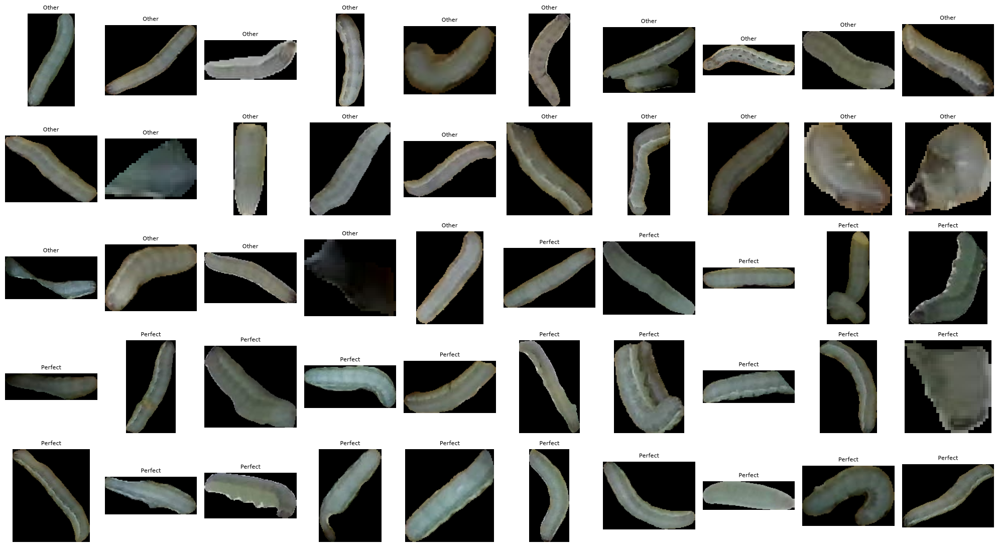

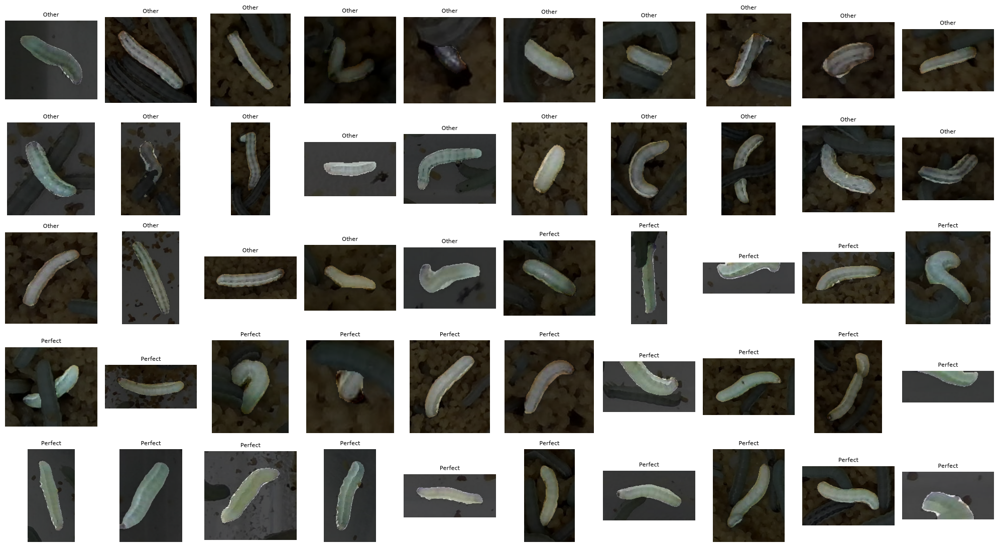

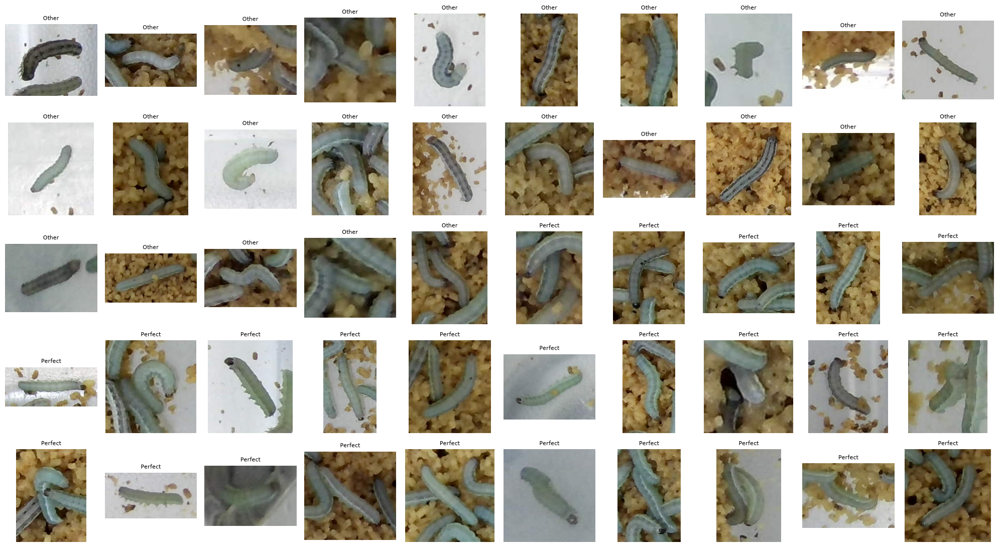

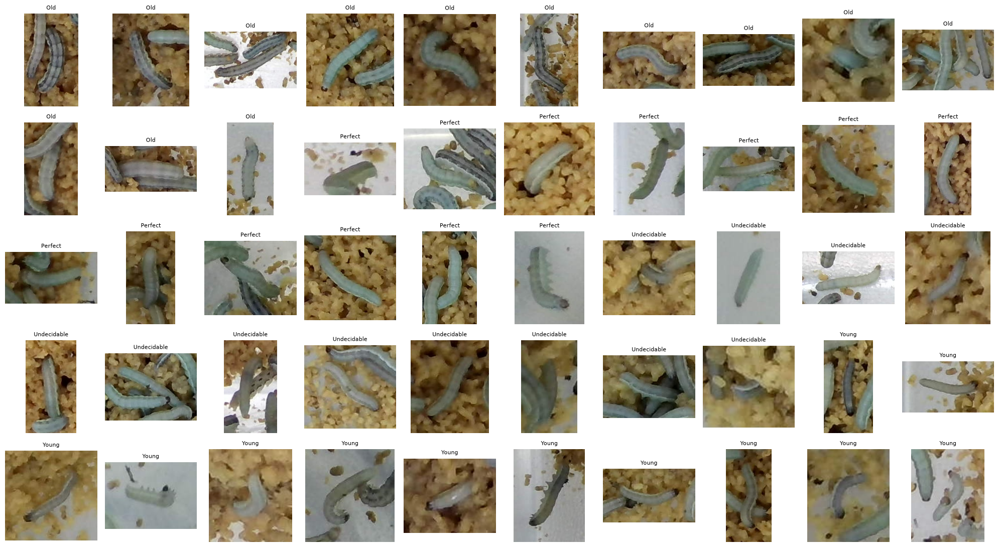

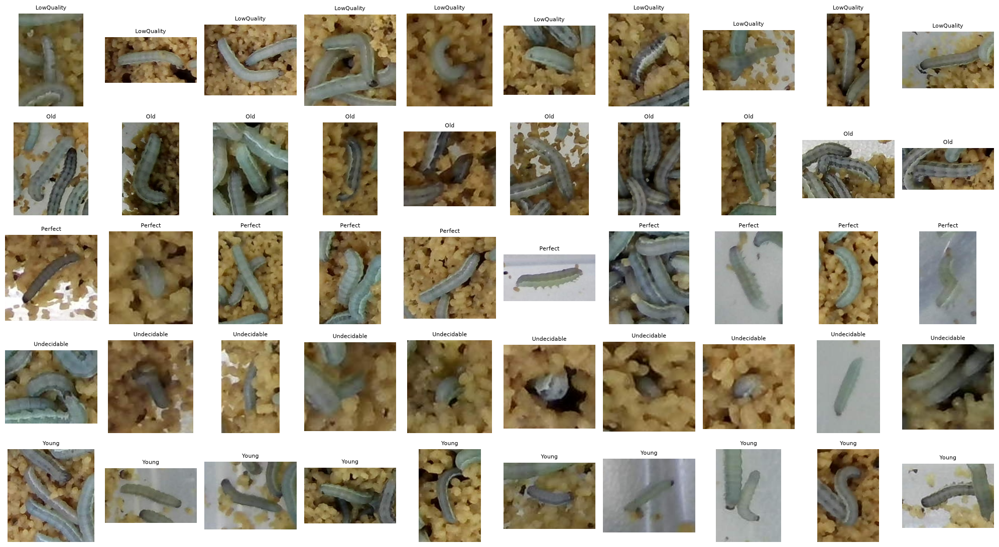

In [78]:
# plot_corpus(cls_folders[0])
for d in cls_folders:
    plot_corpus(d)

## Ranking

In [6]:
raw2cls_df = pd.read_excel(EXPERIMENT_LOG_PATH, sheet_name='2class_raw')

In [81]:
raw2cls_df.loc[[raw2cls_df['test_f1_2class'].idxmax()]]

,family,dataset,variant,best_epoch,seed,total_train_time_sec,train_loss,val_loss,val_accuracy,val_precision,...,val_f1_2class,test_loss,test_accuracy,test_precision,test_recall,test_f1,test_accuracy_2class,test_precision_2class,test_recall_2class,test_f1_2class
1,convnext,2class_raw,convnext_large,2,42,3528.54,0.0754,0.0977,0.8227,0.8253,...,0.8219,0.1041,0.8045,0.8112,0.8045,0.8046,0.8045,0.8112,0.8045,0.8046


In [7]:
def plot_model_ranking(df):
    ranked = df.sort_values('test_f1_2class', ascending=False)

    fig, ax = plt.subplots(figsize=(20, 6))

    # draw bar
    sns.barplot(data=ranked, x='variant', y='test_f1_2class', hue='family', dodge=False, ax=ax, gap=0.1)

    # write score
    for container in ax.containers:
        ax.bar_label(container, fmt='%.4f', fontsize=9, fontweight='bold', padding=3)

    ax.legend(title="family", bbox_to_anchor=(1.01, 1), loc="upper left")

    # เอียง text
    plt.xticks(rotation=60, ha="right", fontsize=9)

    # ตัดช่วงข้อมูล
    ax.set_ylim(0.65, 0.85)

    ax.set_xlabel("Models", fontsize=12, labelpad=15)
    ax.set_ylabel("Test F1 Score (2 classes)", fontsize=12, labelpad=15)
    ax.set_title("Models Ranking", fontsize=15, fontweight='bold', pad=15)
    plt.tight_layout()
    plt.show()

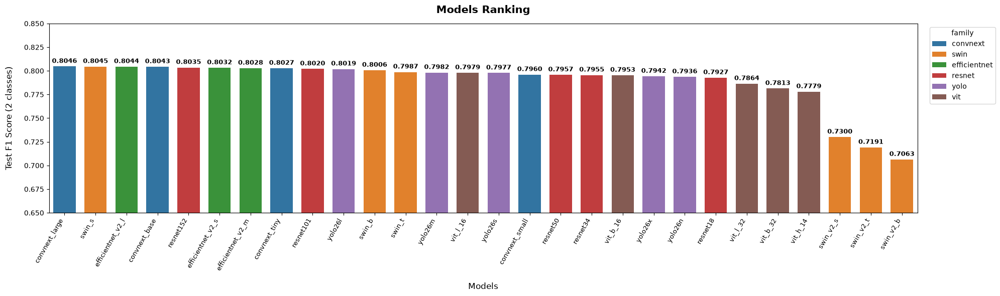

In [8]:
plot_model_ranking(raw2cls_df)

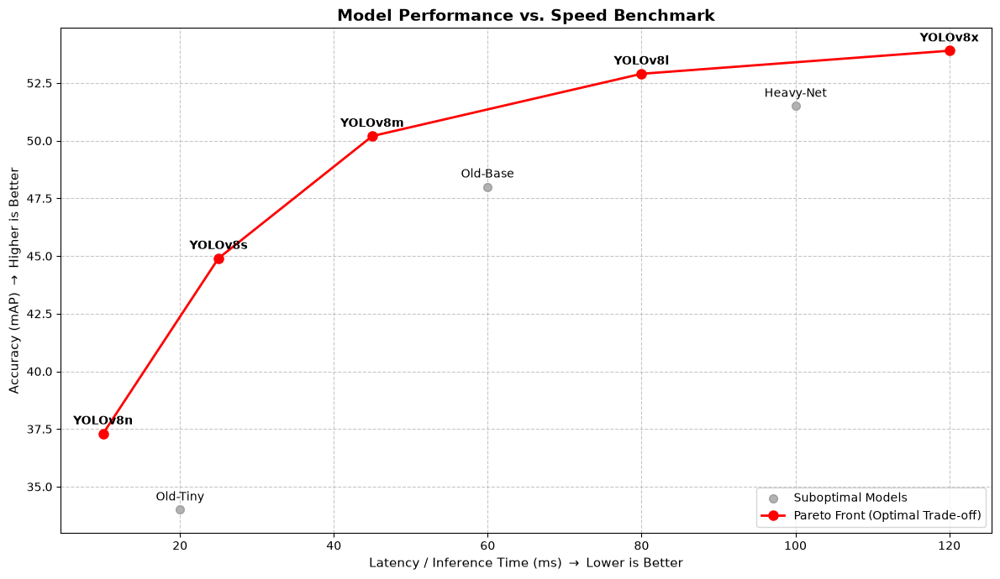

In [43]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Sample Data (Simulating YOLO-style benchmarks)
# 'latency_ms' is our cost (lower is better)
# 'mAP' is our performance (higher is better)
data = {
    'model': ['YOLOv8n', 'YOLOv8s', 'YOLOv8m', 'YOLOv8l', 'YOLOv8x', 'Old-Tiny', 'Old-Base', 'Heavy-Net'],
    'latency_ms': [10, 25, 45, 80, 120, 20, 60, 100],
    'mAP': [37.3, 44.9, 50.2, 52.9, 53.9, 34.0, 48.0, 51.5]
}
df = pd.DataFrame(data)

# 2. Calculate the Pareto Front
# Sort by the cost metric (latency) in ascending order (lowest latency first)
df_sorted = df.sort_values('latency_ms')

pareto_front_x = []
pareto_front_y = []
current_max_map = 0 

# A point is on the Pareto front if its accuracy is higher than all faster models
for index, row in df_sorted.iterrows():
    if row['mAP'] > current_max_map:
        pareto_front_x.append(row['latency_ms'])
        pareto_front_y.append(row['mAP'])
        current_max_map = row['mAP']

# 3. Plotting
fig, ax = plt.subplots(figsize=(12, 7))

# Scatter plot for ALL models
ax.scatter(df['latency_ms'], df['mAP'], color='gray', s=50, alpha=0.6, label='Suboptimal Models')

# Scatter and Line plot for PARETO FRONT models
ax.plot(pareto_front_x, pareto_front_y, marker='o', markersize=8, color='red', 
        linestyle='-', linewidth=2, label='Pareto Front (Optimal Trade-off)')

# Annotate each model with its name
for index, row in df.iterrows():
    # Highlight Pareto models with bolder text if desired, here we just label all
    is_pareto = (row['latency_ms'] in pareto_front_x) and (row['mAP'] in pareto_front_y)
    font_weight = 'bold' if is_pareto else 'normal'
    
    ax.annotate(row['model'], 
                (row['latency_ms'], row['mAP']), 
                textcoords="offset points", 
                xytext=(0, 8), 
                ha='center', 
                fontsize=10,
                fontweight=font_weight)

# Formatting to look like standard benchmark charts
ax.set_xlabel("Latency / Inference Time (ms) $\\rightarrow$ Lower is Better", fontsize=11)
ax.set_ylabel("Accuracy (mAP) $\\rightarrow$ Higher is Better", fontsize=11)
ax.set_title("Model Performance vs. Speed Benchmark", fontsize=14, fontweight='bold')

ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()